# BizAssist AI | Final Colab Notebook
**ITAI 2377 | Group 6 | Huong Nguyen**

One interface for real Coffee Shop sales, simulated POS calculations and business definitions. Results identify their source. Unsupported financial claims are not estimated.


## 1. Load the project
Upload `BizAssist_AI_Final_Group6.zip` to the Colab Files panel, then run this cell. The notebook also works inside an extracted project folder.


In [ ]:
from pathlib import Path
import os
import sys
import zipfile

archive_name = "BizAssist_AI_Final_Group6.zip"
search_dirs = [Path("/content"), Path.cwd()]
archive = next((folder / archive_name for folder in search_dirs if (folder / archive_name).is_file()), None)

if archive is not None:
    target = Path("/content") if Path("/content").exists() else Path.cwd()
    with zipfile.ZipFile(archive) as package:
        package.extractall(target)
    project = target / "BizAssist-AI-Unified"
    print(f"Extracted {archive.name}")
else:
    here = Path.cwd().resolve()
    project = next((folder for folder in (here, here.parent) if (folder / "run_unified.py").exists()), None)
    if project is None:
        raise FileNotFoundError(f"Upload {archive_name} to Colab Files, then rerun this cell.")

os.chdir(project)
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
print("Project folder:", project)
print("Real source data found:", (project / "data/real/raw/Coffee Shop Sales.xlsx").is_file())


## 2. Install dependencies
The first run downloads the pretrained sentence embedding model. CPU runtime is sufficient.

In [2]:
%pip -q install -r requirements.txt

## 3. Run both processing pipelines
**Synthetic:** generate transactions, validate, test refunds/discounts, retrieve knowledge, run 50 synthetic evaluation questions.

**Real:** load the attached Kaggle Excel file, validate it, create daily/store/product features, train and evaluate a Random Forest on a chronological split, and reuse the knowledge retriever.

In [3]:
from run_unified import main
app = main(use_embeddings=True)
print('Available real-data stores:', app.stores)

=== 1/2: SYNTHETIC POS PIPELINE ===
DATA QUALITY
    table  before_rows  before_missing_cells  before_duplicate_rows  after_rows  after_missing_cells  after_duplicate_rows  rejected_rows
  orders         2000                     0                      0        2000                    0                     0              0
   items         4948                     0                      0        4948                    0                     0              0
products           30                     0                      0          30                    0                     0              0
EXAMPLE DAILY METRICS {'date': '2026-11-08', 'gross_sales': 885.58, 'discounts': 24.41, 'refunds': 0.85, 'net_sales': 860.32, 'eligible_order_count': 32, 'aov': 26.89}
FEATURE IMPORTANCE
        feature  importance       std
   order_count  106.451122 31.188667
      avg_hour    2.755149  4.212843
   day_of_week   -0.878986  3.001043
  refund_total   -1.278258  3.041092
discount_total   -4.843896  5

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (7 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

RETRIEVAL SMOKE TEST (NOT FINAL EVALUATION) {'recall_at_3': 1.0, 'median_retrieval_seconds': 0.018652793999990536, 'n_questions': 5, 'tfidf_baseline_recall_at_3': 1.0}

Q: What is net sales? 
A: Net sales are gross sales minus order-level discounts and refunds, each deducted once.

Source: KB002 (Project-authored POS metric dictionary (synthetic demonstration); updated 2026-11-09)
Retrieval: embeddings, score 0.769

Q: What were my net sales on 2026-11-08? 
A: Date: 2026-11-08
Gross sales: $885.58
Discounts: $24.41
Refunds: $0.85
Net sales: $860.32
Eligible completed orders: 32
AOV: $26.89
Formula: net sales = gross sales - discounts - refunds; AOV = net sales / eligible orders.

Q: What was the average order value on 2026-11-08? 
A: Date: 2026-11-08
Gross sales: $885.58
Discounts: $24.41
Refunds: $0.85
Net sales: $860.32
Eligible completed orders: 32
AOV: $26.89
Formula: net sales = gross sales - discounts - refunds; AOV = net sales / eligible orders.

Q: Show top five products by uni

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

REAL DATA QUALITY
                  dataset  raw_rows  valid_rows  rejected_rows  raw_missing_cells  valid_missing_cells  raw_duplicate_transaction_ids  unique_stores  unique_products start_date   end_date
Kaggle Coffee Shop Sales    149116      149116              0                  0                    0                              0              3               80 2023-01-01 2023-06-30
REAL MODEL EVALUATION {'train_days': 135, 'test_days': 46, 'test_r2': 0.3332832509429592, 'test_mae': 344.25354498705883, 'baseline_mae': 2100.3859742351046}
REAL DATA SALES SUMMARY {'start': None, 'end': None, 'store': 'All stores', 'currency': 'USD (assumed from NYC location; not explicit in source)', 'gross_transaction_revenue': 698812.33, 'transaction_count': 149116, 'units_sold': 214470, 'gross_aov': 4.69, 'note': 'Gross transaction revenue only; discounts, refunds and verified net sales are unavailable.'}
Available real-data stores: ['All stores', 'Astoria', "Hell's Kitchen", 'Lower Manhattan']

## 4. Inspect data quality and model metrics
The two data sources have different financial semantics; do not merge their sales totals.

In [4]:
import pandas as pd
from IPython.display import display
for filename in [
    'reports/results/quality_metrics.csv',
    'reports/results/dirty_data_quality.csv',
    'reports/results/coffee_shop_quality.csv',
    'reports/results/evaluation_summary.csv',
    'reports/results/coffee_shop_model_metrics.csv',
]:
    print('\n', filename)
    display(pd.read_csv(filename))


 reports/results/quality_metrics.csv


,table,before_rows,before_missing_cells,before_duplicate_rows,after_rows,after_missing_cells,after_duplicate_rows,rejected_rows
0,orders,2000,0,0,2000,0,0,0
1,items,4948,0,0,4948,0,0,0
2,products,30,0,0,30,0,0,0



 reports/results/dirty_data_quality.csv


,table,before_rows,before_missing_cells,before_duplicate_rows,after_rows,after_missing_cells,after_duplicate_rows,rejected_rows
0,orders,2001,1,1,1697,0,0,304
1,items,4949,0,1,4061,0,0,888
2,products,30,1,0,29,0,0,1



 reports/results/coffee_shop_quality.csv


,dataset,raw_rows,valid_rows,rejected_rows,raw_missing_cells,valid_missing_cells,raw_duplicate_transaction_ids,unique_stores,unique_products,start_date,end_date
0,Kaggle Coffee Shop Sales,149116,149116,0,0,0,0,3,80,2023-01-01,2023-06-30



 reports/results/evaluation_summary.csv


,retrieval_recall_at_3,tfidf_baseline_recall_at_3,numeric_correctness,grounded_answer_accuracy,citation_support,unsupported_query_handling,median_response_latency_seconds,total_questions
0,1.0,1.0,1.0,0.9,0.9,1.0,0.001399,50



 reports/results/coffee_shop_model_metrics.csv


,train_days,test_days,test_r2,test_mae,baseline_mae
0,135,46,0.333283,344.253545,2100.385974


## 5. Review visualizations and feature importance

reports/figures/dirty_data_before_after.png


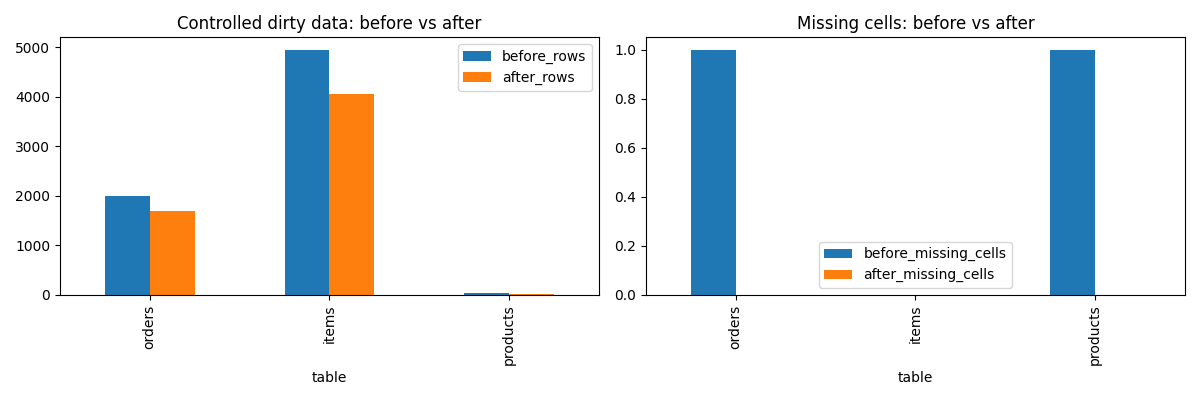

reports/figures/feature_importance.png


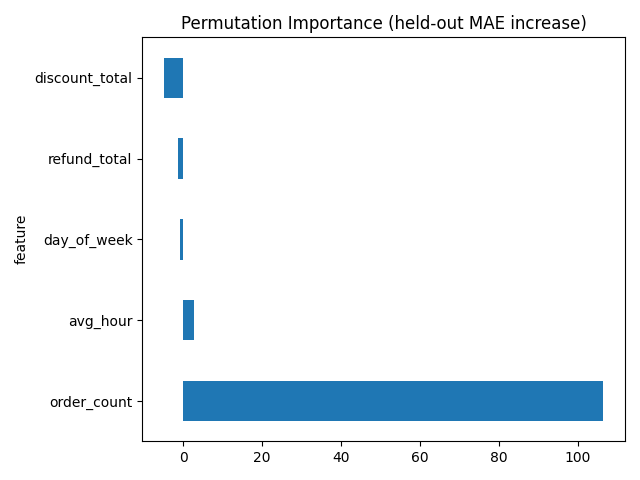

reports/figures/coffee_shop_before_after.png


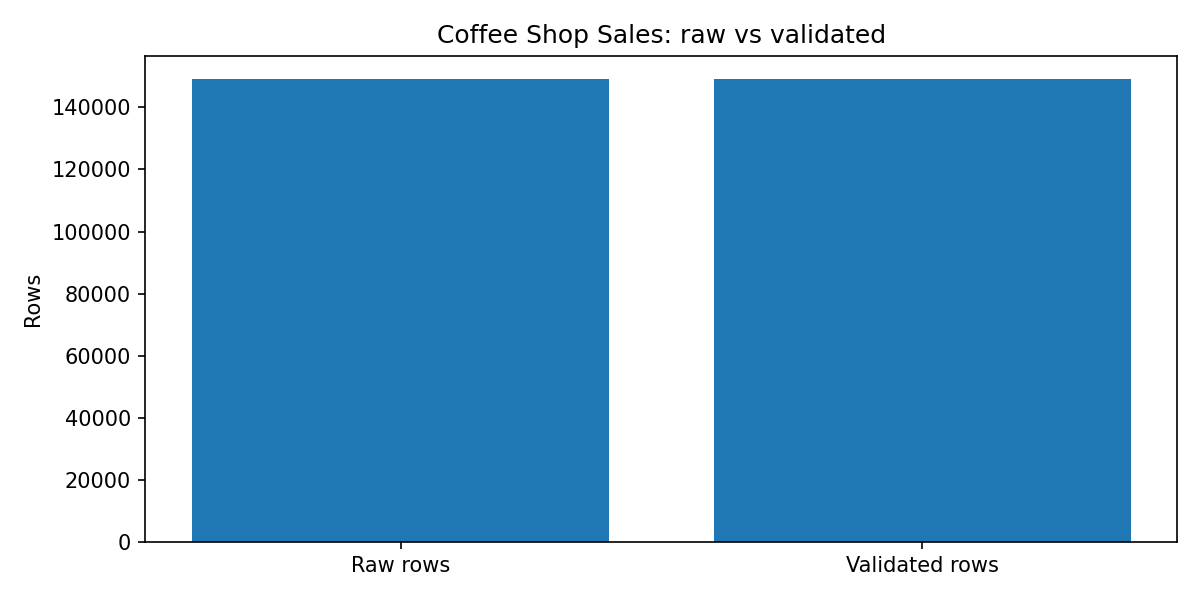

reports/figures/coffee_shop_daily_revenue.png


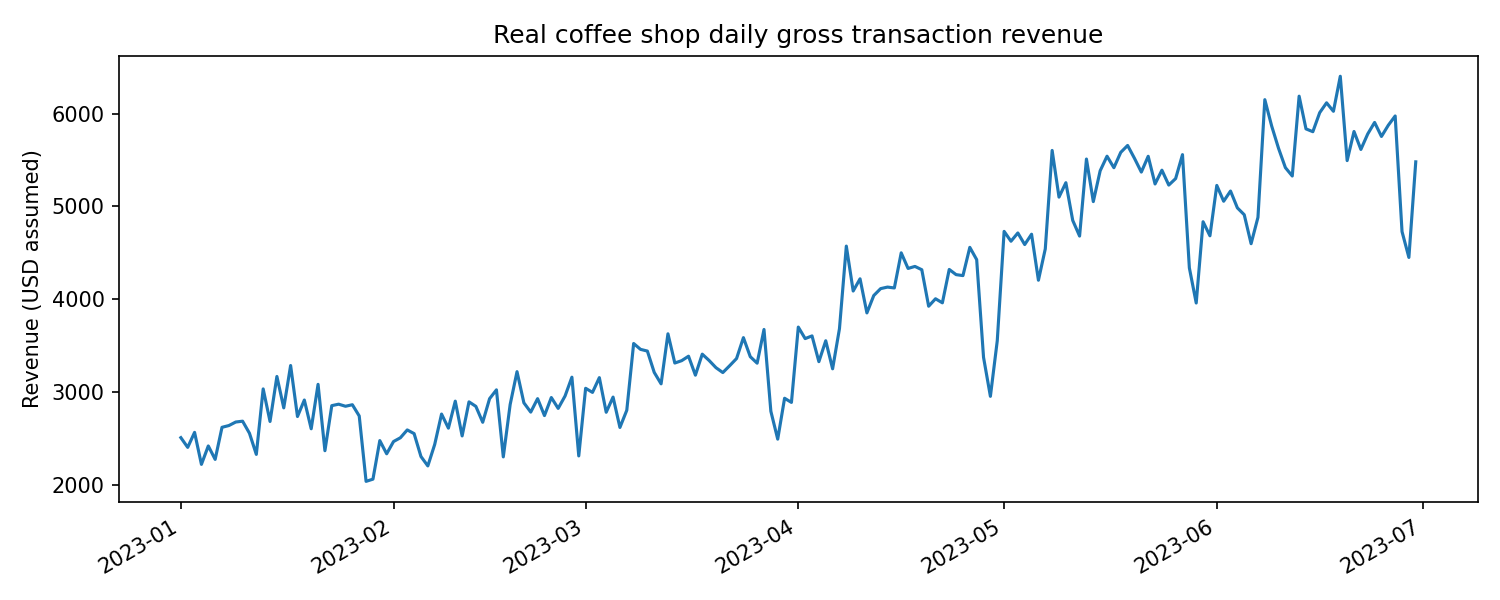

reports/figures/coffee_shop_feature_importance.png


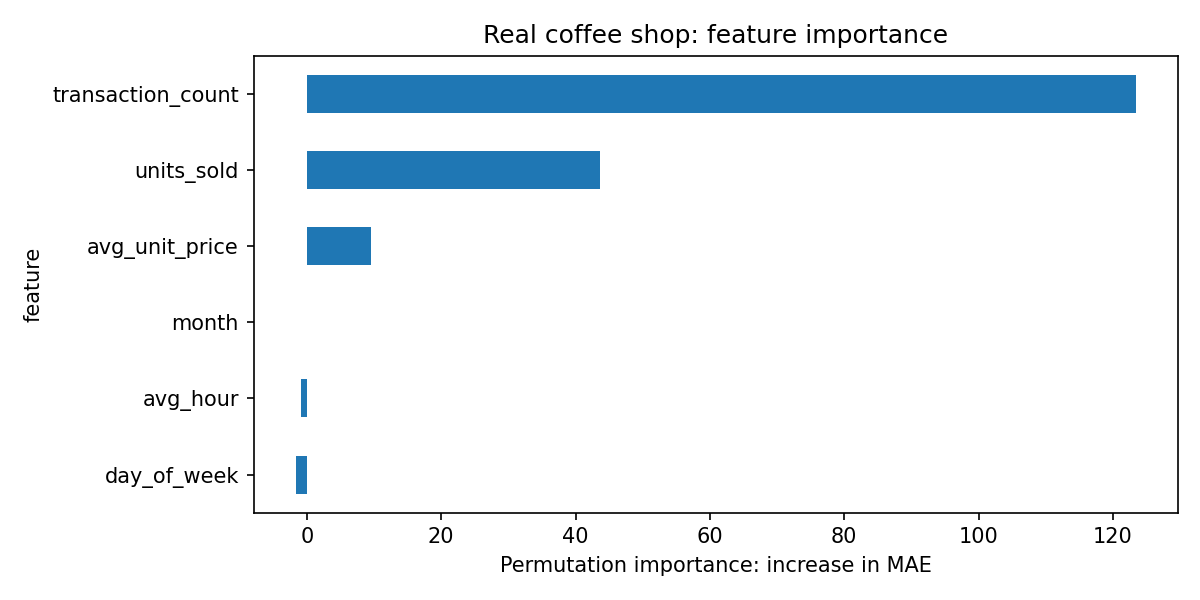

In [5]:
from IPython.display import Image, display
for figure in [
    'reports/figures/dirty_data_before_after.png',
    'reports/figures/feature_importance.png',
    'reports/figures/coffee_shop_before_after.png',
    'reports/figures/coffee_shop_daily_revenue.png',
    'reports/figures/coffee_shop_feature_importance.png',
]:
    print(figure)
    display(Image(filename=figure))

## 6. Demonstrate both datasets
The real dataset reports **gross transaction revenue**; it does not support verified net sales. The synthetic dataset supports refunds, discounts, and net sales.

In [6]:
examples = [
    ('Real Coffee Shop (Kaggle)', 'What were gross sales in March 2023?'),
    ('Real Coffee Shop (Kaggle)', 'Show top five products by units sold from 2023-03-01 to 2023-03-31'),
    ('Real Coffee Shop (Kaggle)', 'What was the busiest hour?'),
    ('Real Coffee Shop (Kaggle)', 'What were net sales in March 2023?'),
    ('Synthetic POS', 'What were my net sales on 2026-11-08?'),
    ('Synthetic POS', 'What is average order value?'),
]
for dataset, question in examples:
    print('\nDATASET:', dataset, '\nQ:', question)
    print('A:', app.answer(question, dataset=dataset))


DATASET: Real Coffee Shop (Kaggle) 
Q: What were gross sales in March 2023?
A: Store: All stores | Period: 2023-03-01 to 2023-03-31
Gross transaction revenue: $98,834.68 (USD assumed)
Transactions: 21,229 | Units: 30,406
Gross AOV: $4.66
Gross transaction revenue only; discounts, refunds and verified net sales are unavailable.

DATASET: Real Coffee Shop (Kaggle) 
Q: Show top five products by units sold from 2023-03-01 to 2023-03-31
A: Top 5 products by units (2023-03-01 to 2023-03-31; All stores):
 product_id            product_detail  units  gross_revenue
         50              Earl Grey Rg    685        1712.50
         26              Brazilian Rg    681        2043.00
         54   Morning Sunrise Chai Rg    680        1700.00
         36  Jamaican Coffee River Lg    673        2523.75
         29 Columbian Medium Roast Rg    658        1645.00

DATASET: Real Coffee Shop (Kaggle) 
Q: What was the busiest hour?
A: Busiest hour: 10:00 (18,545 transactions; All stores).

DATASET: R

## 7. Independent manual evaluation
The 30 fixed cases were written separately from the generated 50 case set. They compare assistant answers with raw data calculations. Passing fixed cases does not prove general accuracy.


In [7]:
from bizassist.manual_evaluation import evaluate_manual
manual_summary, manual_results = evaluate_manual(app)
display(manual_summary)
print('Failures:', int((~manual_results.passed).sum()))
display(manual_results.loc[~manual_results.passed, ['dataset','id','question','expected','actual_answer']])
print('Saved: reports/results/manual_evaluation_results_30.csv and manual_evaluation_summary.csv')


,dataset,kind,cases,passed,accuracy,median_latency_seconds
0,real,ranking,2,2,1.0,0.081365
1,real,revenue,11,11,1.0,0.050100
2,real,unsupported,2,2,1.0,0.000039
3,synthetic,knowledge,5,5,1.0,0.023100
4,synthetic,numeric,5,5,1.0,0.001338
5,synthetic,ranking,2,2,1.0,0.013651
6,synthetic,unsupported,3,3,1.0,0.000018
7,real,ALL,15,15,1.0,0.050100
8,synthetic,ALL,15,15,1.0,0.001550


Failures: 0


,dataset,id,question,expected,actual_answer


Saved: reports/results/manual_evaluation_results_30.csv and manual_evaluation_summary.csv


**Interpretation:** Compare the two data sources separately. A failed case is evidence of a limitation or bug; do not silently delete or rewrite the case. The real data supports gross transaction revenue but not verified net sales, refunds, or profit. These tests do not measure generalization to unseen businesses.


## 8. Launch the unified Gradio app
Choose a **Common questions** preset or type a question. The system automatically selects the source using the question context. Optionally filter a real 2023 store. If a request is ambiguous, the assistant asks for clarification.


In [8]:
from run_unified import make_interface
ui = make_interface(app)
ui.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 9. Run automated tests
The financial and real-coffee-shop tests cover separate business rules.

In [9]:
!python -m pytest -q tests/

.........                                                                [100%]
9 passed in 51.93s


## 10. Export evidence
Save the results, figures, test cases and source files after running the pipeline. The exported archive is supporting evidence, not a replacement for the PDF report or the Colab notebook.


In [11]:
from pathlib import Path
import shutil, zipfile
from datetime import datetime
from IPython.display import display, FileLink

# Save all generated results, charts, evaluation cases, source code, tests,
# documentation, and original datasets in one reproducibility archive.
# This does NOT include model cache or virtual environment.
project_root = Path.cwd()
export_name = 'BizAssist_AI_Evaluation_Outputs_Group6.zip'
export_path = Path('/content') / export_name if Path('/content').exists() else project_root.parent / export_name
include = ['reports', 'evaluation', 'data', 'bizassist', 'tests', 'docs',
           'run.py', 'run_coffee_shop.py', 'run_unified.py', 'requirements.txt', 'README.md', 'notebooks']
with zipfile.ZipFile(export_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=6) as archive:
    for rel in include:
        path = project_root / rel
        if not path.exists():
            print('Not found, skipped:', rel)
            continue
        for f in ([path] if path.is_file() else path.rglob('*')):
            if f.is_file() and '__pycache__' not in f.parts and '.pytest_cache' not in f.parts and f.suffix != '.pyc':
                archive.write(f, arcname=str(Path('BizAssist-AI-Unified') / f.relative_to(project_root)))
print(f'Created: {export_path} ({export_path.stat().st_size / (1024**2):.1f} MB)')
display(FileLink(str(export_path)))
# In Colab, run this manually to trigger a browser download:
# from google.colab import files
# files.download(str(export_path))


Created: /content/BizAssist_Final_Submission_Outputs.zip (13.8 MB)


/content/BizAssist_Final_Submission_Outputs.zip

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Submission checklist and limitations
1. Submit `FN_HuongNguyen_Group6_ITAI2377.pdf`. Add your public view only Colab link to the PDF.
2. Keep this notebook and the source ZIP available for the live demo.
3. Use the generated charts and metrics as evidence. The 50 generated cases are not an independent benchmark.
4. Real data supports gross sales but not verified net sales. Its currency is assumed USD.
5. The real data revenue model uses same day inputs and is not a future forecast.
6. Group 6 has one member, Huong Nguyen, responsible for the complete implementation.
